### Clusterização K-Means - Spotify (Audio Features)

**Objetivo**:
Identificar padrões sonoros que atravessem gêneros musicais, a partir de 8 audio features de músicas do Spotify (danceability, energy, loudness, speechiness, acousticness, instrumentalness, valence e tempo).

**Abordagens**
- **Baseline:** K-Means nas 8 features escaladas, sem redução de dimensionalidade.
- **PCA:** K-Means nos primeiros 3, 4 e 5 componentes principais, número sugerido no notebook do Victor a partir da variância explicada.

**Critérios de sucesso do MVP**
- **Similaridade sonora:** os clusters são compactos e bem separados? (silhouette e Davies-Bouldin)
- **Diversidade de gêneros:** os clusters misturam gêneros em vez de reproduzi-los? (gênero dominante e entropia de gêneros)

In [10]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Adiciona a pasta raiz do projeto ao caminho de busca (o preprocessing.py fica fora da pasta notebooks)
sys.path.append("..")

from preprocessing import preprocessing
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

# Define o número de CPUs usado pelo joblib/loky (evita o aviso de contagem de núcleos)
os.environ["LOKY_MAX_CPU_COUNT"] = "8"

### Spotify Tracks Dataset

In [11]:
# Carrega dados de músicas do Spotify
df = pd.read_csv("../raw_data/spotify-tracks-dataset-detailed.csv")
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [12]:
# Verifica quantidade de linhas da base
len(df)

114000

### 1. Pre Processing

- A função `preprocessing` reúne todas as etapas de preparação da base em um único lugar, para que o mesmo tratamento possa ser reaplicado de forma idêntica. As etapas, nesta ordem, são: remoção do gênero comedy, seleção das colunas necessárias, remoção de valores nulos, remoção de duplicatas exatas, preservação de todos os gêneros de cada música (uma música pode aparecer em mais de um gênero), manutenção de uma linha por música, separação entre metadados e features e escalonamento das features.

- Para o escalonamento foi adotado o StandardScaler, que padroniza os valores para média 0 e desvio padrão 1. Como o K-Means é baseado em distância, features em escalas muito diferentes (como loudness e tempo, em relação às variáveis entre 0 e 1) dominariam o cálculo se não fossem padronizadas. O scaler foi ajustado na base completa, uma vez que não há divisão entre treino e teste na clusterização.

#### 1.1 Aplicação do Pre Processing

In [14]:
# Aplica o pre processing na base
X_scaled, df_metadata, scaler, features = preprocessing(df)

In [15]:
# Verifica o formato da matriz de features escaladas
X_scaled.shape

(88751, 8)

In [16]:
# Verifica os metadados das músicas
df_metadata.head()

,track_id,artists,track_name,genres
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,"[acoustic, j-pop, singer-songwriter, songwriter]"
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost - Acoustic,"[acoustic, chill]"
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,[acoustic]
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Can't Help Falling In Love,[acoustic]
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,[acoustic]


In [17]:
# Cria o dataframe com as features escaladas
df_scaled = pd.DataFrame(X_scaled, columns=features)
df_scaled.head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
0,0.642976,-0.671544,0.331501,0.761537,-0.866112,-0.539305,0.931651,-1.143959
1,-0.800829,-1.818558,-1.676941,-0.043998,1.782308,-0.539291,-0.769508,-1.490966
2,-0.699312,-1.068138,-0.240643,-0.292784,-0.338091,-0.539308,-1.327701,-1.529466
3,-1.669368,-2.232261,-1.922037,-0.527078,1.725883,-0.539091,-1.240365,1.978131
4,0.315863,-0.741531,-0.230495,-0.330223,0.431074,-0.539308,-1.149232,-0.078050


In [18]:
# Une os metadados com as features escaladas
df_final = pd.concat([df_metadata, df_scaled], axis=1)
df_final.head()

,track_id,artists,track_name,genres,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,"[acoustic, j-pop, singer-songwriter, songwriter]",0.642976,-0.671544,0.331501,0.761537,-0.866112,-0.539305,0.931651,-1.143959
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost - Acoustic,"[acoustic, chill]",-0.800829,-1.818558,-1.676941,-0.043998,1.782308,-0.539291,-0.769508,-1.490966
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,[acoustic],-0.699312,-1.068138,-0.240643,-0.292784,-0.338091,-0.539308,-1.327701,-1.529466
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Can't Help Falling In Love,[acoustic],-1.669368,-2.232261,-1.922037,-0.527078,1.725883,-0.539091,-1.240365,1.978131
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,[acoustic],0.315863,-0.741531,-0.230495,-0.330223,0.431074,-0.539308,-1.149232,-0.078050


- Energy, loudness e acousticness são fortemente correlacionadas e pesam como um único eixo de "intensidade" na distância dos algoritmos.
- Speechiness, instrumentalness e acousticness têm distribuição muito assimétrica, e loudness e duration têm outliers. Isso afeta o `StandardScaler`.

### 2. Funções Auxiliares de Avaliação

Para comparar baseline e PCA de forma justa, todo modelo passa pelas mesmas métricas:

- **Silhouette** (maior = melhor): calculado em 3 amostras diferentes de 10 mil músicas, com média e desvio. Isso responde à dúvida sobre a estabilidade do `sample_size=10000`.
- **Davies-Bouldin** (menor = melhor).
- **silhouette_8d / davies_bouldin_8d:** os mesmos índices, mas calculados no espaço original das 8 features. Como o silhouette de cada modelo é medido no espaço em que ele foi treinado (8, 3, 4 ou 5 dimensões), ele não é comparável entre baseline e PCA. As versões `_8d` colocam todos os modelos no mesmo referencial.
- **genero_dominante_pct** (menor = mais misturado) e **entropia_generos** (maior = mais diverso): ligadas ao critério de diversidade de gêneros do MVP. Elas não servem sozinhas, porque um único cluster gigante teria a maior mistura possível. Por isso o tamanho dos clusters também entra na tabela.

#### 2.1 Métricas de Gêneros

In [19]:
# Cria uma linha por par música-gênero
genres_exp = df_metadata["genres"].explode().rename("genre")

# Conta a quantidade de gêneros distintos (usada para normalizar a entropia)
N_GENEROS = genres_exp.nunique()

In [20]:
def metricas_genero(labels):
    """Mede o quanto os clusters misturam gêneros (ligado ao critério de diversidade de gêneros do MVP).

    labels: pd.Series com o cluster de cada música (índice = índice de df_metadata). Ruído deve ser removido antes.
    - genero_dominante_pct: share do gênero mais comum em cada cluster, ponderado pelo tamanho do cluster (menor = mais misturado)
    - entropia_generos: entropia normalizada (0 a 1) da distribuição de gêneros em cada cluster, ponderada pelo tamanho (maior = mais diverso)
    """
    # Cruza os gêneros de cada música com o seu cluster
    g = genres_exp.to_frame().join(labels.rename("cluster"), how="inner")

    # Conta a quantidade de músicas por cluster e gênero
    tab = g.groupby(["cluster", "genre"]).size().unstack(fill_value=0)

    # Calcula a distribuição de gêneros dentro de cada cluster e o peso (tamanho) de cada cluster
    p = tab.div(tab.sum(axis=1), axis=0)
    peso = tab.sum(axis=1) / tab.values.sum()

    # Calcula o gênero dominante e a entropia, ponderados pelo tamanho do cluster
    dominante = (p.max(axis=1) * peso).sum() * 100
    entropia = (-(p * np.log(p.where(p > 0, 1))).sum(axis=1) / np.log(N_GENEROS) * peso).sum()
    return {"genero_dominante_pct": dominante, "entropia_generos": entropia}

#### 2.2 Perfil dos Clusters

In [21]:
def perfil_clusters(labels, top_n=3):
    """Média das 8 features (escaladas) por cluster, tamanho do cluster e gêneros mais comuns. Ignora ruído (-1)."""
    # Remove o ruído (-1) e nomeia a série de clusters
    labels = labels[labels != -1].rename("cluster")

    # Calcula a média de cada feature escalada por cluster
    medias = df_scaled.loc[labels.index].groupby(labels).mean()

    # Identifica os gêneros mais comuns de cada cluster
    g = genres_exp.to_frame().join(labels, how="inner")
    top = g.groupby("cluster")["genre"].agg(lambda s: ", ".join(s.value_counts().head(top_n).index))

    # Monta o perfil com o percentual de músicas e os gêneros mais comuns
    perfil = medias.copy()
    perfil["pct_musicas"] = labels.value_counts(normalize=True).sort_index() * 100
    perfil["top_generos"] = top
    return perfil


def plot_perfil(perfil, titulo, ax):
    """Heatmap com a média de cada feature (em desvios-padrão) por cluster."""
    medias = perfil[features]
    im = ax.imshow(medias.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(range(len(features)))
    ax.set_xticklabels(features, rotation=45, ha="right")
    ax.set_yticks(range(len(medias)))
    ax.set_yticklabels([f"c{c} ({p:.0f}%)" for c, p in zip(medias.index, perfil["pct_musicas"])])
    ax.set_title(titulo)
    return im

#### 2.3 Silhouette com Amostras Repetidas

In [22]:
# Define as sementes e o tamanho das amostras usadas no silhouette
SEEDS_SILHOUETTE = [0, 1, 2]
TAMANHO_AMOSTRA_SIL = 10000


def silhouette_amostrado(X_modelo, labels):
    """Silhouette em amostras de 10 mil músicas, repetido com 3 sementes (média e desvio)."""
    # Calcula o silhouette para cada semente
    notas = [
        silhouette_score(X_modelo, labels, sample_size=TAMANHO_AMOSTRA_SIL, random_state=s)
        for s in SEEDS_SILHOUETTE
    ]
    return np.mean(notas), np.std(notas)

#### 2.4 Varredura de k

In [23]:
def varrer_k(X_modelo, nome, ks=range(2, 16)):
    """Treina o K-Means para cada k e retorna inertia (elbow), silhouette e Davies-Bouldin."""
    linhas = []
    for k in ks:
        # Treina o K-Means e obtém o cluster de cada música
        km = KMeans(n_clusters=k, n_init=10, random_state=42)
        labels = km.fit_predict(X_modelo)

        # Calcula as métricas de avaliação do modelo
        sil_media, sil_std = silhouette_amostrado(X_modelo, labels)
        linhas.append({
            "espaco": nome,
            "k": k,
            "inertia": km.inertia_,
            "silhouette": sil_media,
            "silhouette_std": sil_std,
            "davies_bouldin": davies_bouldin_score(X_modelo, labels),
        })
        print(f"{nome} | K={k} | Silhouette={sil_media:.4f} (±{sil_std:.4f})")
    return pd.DataFrame(linhas)


def plot_varredura(res, titulo):
    """Plota Elbow, Silhouette (média ± desvio) e Davies-Bouldin para cada espaço da varredura."""
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for nome, d in res.groupby("espaco", sort=False):
        axes[0].plot(d["k"], d["inertia"], marker="o", label=nome)
        axes[1].errorbar(d["k"], d["silhouette"], yerr=d["silhouette_std"], marker="o", capsize=2, label=nome)
        axes[2].plot(d["k"], d["davies_bouldin"], marker="o", label=nome)
    axes[0].set_title("Elbow Method")
    axes[0].set_ylabel("Within-Cluster Sums of Squares")
    axes[1].set_title("Silhouette (média ± desvio de 3 amostras)")
    axes[2].set_title("Davies-Bouldin (menor = melhor)")
    for ax in axes:
        ax.set_xlabel("Number of clusters")
        ax.grid(alpha=0.3)
    axes[1].legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

### 3. Baseline Pipeline - K-Means (8 features)

Adotei o K-Means nas 8 features escaladas, sem redução de dimensionalidade, como modelo baseline. Foi realizada a varredura de k de 2 a 15 (elbow, silhouette e Davies-Bouldin), com o silhouette repetido em 3 amostras. A célula da varredura leva alguns minutos para rodar.

#### 3.1 Espaço do Modelo

In [24]:
# Define os espaços em que cada modelo vai rodar, começando pelo baseline (8 features escaladas)
espacos = {"Baseline (8 features)": X_scaled}

#### 3.2 Varredura de k

In [25]:
# Varre k de 2 a 15 no baseline e calcula inertia, silhouette e Davies-Bouldin
res_baseline = varrer_k(espacos["Baseline (8 features)"], "Baseline (8 features)")

Baseline (8 features) | K=2 | Silhouette=0.2877 (±0.0017)
Baseline (8 features) | K=3 | Silhouette=0.1827 (±0.0009)
Baseline (8 features) | K=4 | Silhouette=0.1934 (±0.0005)
Baseline (8 features) | K=5 | Silhouette=0.2021 (±0.0013)
Baseline (8 features) | K=6 | Silhouette=0.2105 (±0.0010)
Baseline (8 features) | K=7 | Silhouette=0.1936 (±0.0014)
Baseline (8 features) | K=8 | Silhouette=0.1801 (±0.0010)
Baseline (8 features) | K=9 | Silhouette=0.1804 (±0.0008)
Baseline (8 features) | K=10 | Silhouette=0.1797 (±0.0010)
Baseline (8 features) | K=11 | Silhouette=0.1800 (±0.0009)
Baseline (8 features) | K=12 | Silhouette=0.1705 (±0.0006)
Baseline (8 features) | K=13 | Silhouette=0.1685 (±0.0012)
Baseline (8 features) | K=14 | Silhouette=0.1674 (±0.0017)
Baseline (8 features) | K=15 | Silhouette=0.1689 (±0.0020)


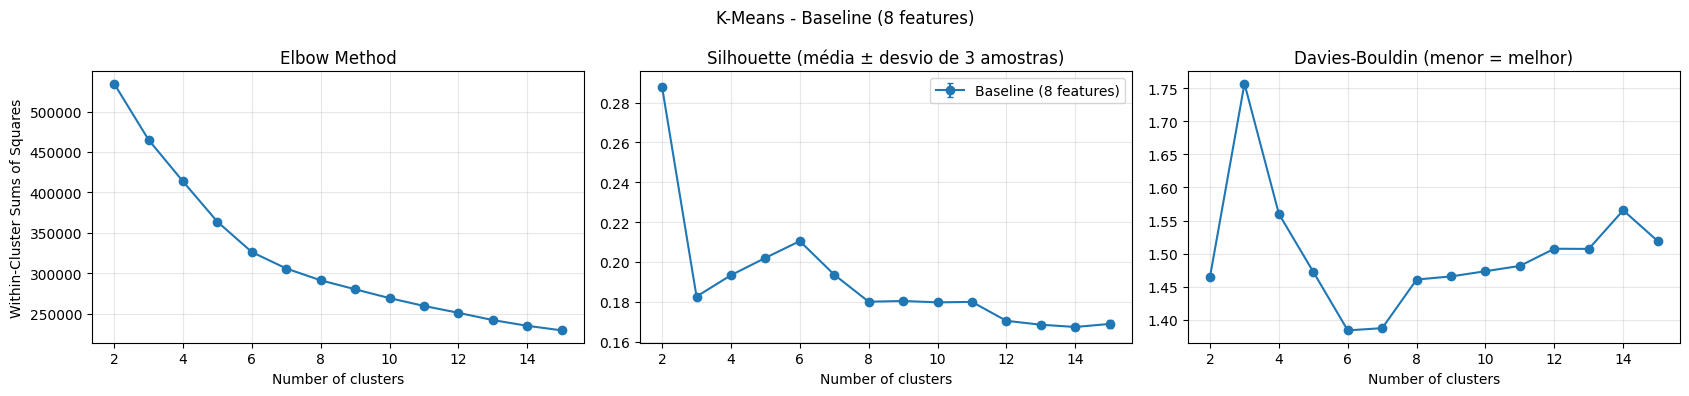

In [26]:
# Elbow, silhouette e Davies-Bouldin por k: avaliam a compactação e a separação dos clusters.
plot_varredura(res_baseline, "K-Means - Baseline (8 features)")

Resultados da rodada com a base completa (88.751 músicas, `random_state=42`).

O cotovelo costuma ficar em k=4 e o silhouette em k=6, mas a leitura do elbow é subjetiva. Por isso optei por comparar os dois valores (`K_COMPARACAO = [4, 6]`) em todos os modelos mais adiante.

- **k=2** tem o maior silhouette (0,288), mas provavelmente só divide o eixo de intensidade (calmo vs energético), pouco útil para o recomendador.
- **k=6** é o melhor entre os valores maiores (0,210), único pico local (k=4: 0,193; k=5: 0,202). O desvio entre as 3 amostras de silhouette é de no máximo ~0,002, então a ordem entre os k é estável.
- Silhouette ~0,2 indica clusters **sobrepostos**, comum em audio features do Spotify, que formam mais um contínuo do que grupos separados.

### 4. Improve the Baseline Pipeline - PCA

Seguindo o gráfico de variância explicada do PCA, optei por testar **3, 4 e 5 componentes**.

Com 8 componentes o PCA é só uma rotação dos dados, que preserva as distâncias. Rodar o modelo nos 8 PCs daria o mesmo resultado do baseline, então só faz sentido usar menos componentes.

#### 4.1 Variância Explicada

In [27]:
# Ajusta o PCA com todos os componentes (mesmo PCA do Victor, 8 componentes)
pca_full = PCA().fit(X_scaled)

# Calcula a variância explicada e acumulada por componente
variancia = pd.DataFrame({
    "PC": [f"PC{i}" for i in range(1, len(features) + 1)],
    "variancia_explicada": pca_full.explained_variance_ratio_,
    "variancia_acumulada": np.cumsum(pca_full.explained_variance_ratio_),
})
variancia.round(4)

,PC,variancia_explicada,variancia_acumulada
0,PC1,0.3656,0.3656
1,PC2,0.1753,0.5410
2,PC3,0.1218,0.6627
3,PC4,0.1126,0.7753
4,PC5,0.1049,0.8802
5,PC6,0.0612,0.9414
6,PC7,0.0407,0.9821
7,PC8,0.0179,1.0000


Os 3 primeiros PCs explicam só ~66% da variância, enquanto os 5 primeiros explicam ~88%.

#### 4.2 Loadings

In [28]:
# Calcula o peso de cada feature nos 5 primeiros componentes
loadings = pd.DataFrame(
    pca_full.components_.T,
    index=features,
    columns=[f"PC{i}" for i in range(1, len(features) + 1)]
)

loadings.iloc[:, :5].round(2)

,PC1,PC2,PC3,PC4,PC5
danceability,0.26,0.53,0.14,-0.25,0.40
energy,0.50,-0.30,-0.05,-0.17,0.02
loudness,0.51,-0.09,-0.16,-0.03,-0.20
speechiness,0.15,0.05,0.94,-0.01,-0.28
acousticness,-0.44,0.35,0.03,0.31,-0.09
instrumentalness,-0.28,-0.35,0.22,-0.38,0.67
valence,0.30,0.54,-0.08,0.12,0.31
tempo,0.20,-0.28,0.14,0.81,0.42


#### 4.3 Espaços com PCA

In [29]:
# Define a quantidade de componentes testados
N_COMPONENTES = [3, 4, 5]

# Cria os espaços reduzidos do PCA e adiciona aos espaços do modelo
for n in N_COMPONENTES:
    espacos[f"PCA {n}"] = PCA(n_components=n).fit_transform(X_scaled)

In [30]:
# Verifica o formato de cada espaço (baseline e PCA com 3, 4 e 5 componentes)
for nome, M in espacos.items():
    print(nome, M.shape)

Baseline (8 features) (88751, 8)
PCA 3 (88751, 3)
PCA 4 (88751, 4)
PCA 5 (88751, 5)


#### 4.4 Varredura de k

Mesma varredura de k do baseline, agora nos espaços reduzidos do PCA. O elbow tem escala diferente em cada espaço (a inertia depende do número de dimensões), então vale olhar o formato da curva, não o valor absoluto.

In [31]:
# Varre k de 2 a 15 em cada espaço do PCA e calcula inertia, silhouette e Davies-Bouldin
res_pca = pd.concat(
    [varrer_k(espacos[f"PCA {n}"], f"PCA {n}") for n in N_COMPONENTES],
    ignore_index=True
)

PCA 3 | K=2 | Silhouette=0.4001 (±0.0009)
PCA 3 | K=3 | Silhouette=0.3042 (±0.0021)
PCA 3 | K=4 | Silhouette=0.3311 (±0.0021)
PCA 3 | K=5 | Silhouette=0.3402 (±0.0025)
PCA 3 | K=6 | Silhouette=0.2883 (±0.0033)
PCA 3 | K=7 | Silhouette=0.2907 (±0.0015)
PCA 3 | K=8 | Silhouette=0.2846 (±0.0003)
PCA 3 | K=9 | Silhouette=0.2860 (±0.0006)
PCA 3 | K=10 | Silhouette=0.2843 (±0.0012)
PCA 3 | K=11 | Silhouette=0.2700 (±0.0008)
PCA 3 | K=12 | Silhouette=0.2749 (±0.0006)
PCA 3 | K=13 | Silhouette=0.2604 (±0.0006)
PCA 3 | K=14 | Silhouette=0.2640 (±0.0033)
PCA 3 | K=15 | Silhouette=0.2590 (±0.0014)
PCA 4 | K=2 | Silhouette=0.3503 (±0.0014)
PCA 4 | K=3 | Silhouette=0.2477 (±0.0014)
PCA 4 | K=4 | Silhouette=0.2648 (±0.0011)
PCA 4 | K=5 | Silhouette=0.2685 (±0.0014)
PCA 4 | K=6 | Silhouette=0.2731 (±0.0011)
PCA 4 | K=7 | Silhouette=0.2411 (±0.0009)
PCA 4 | K=8 | Silhouette=0.2285 (±0.0015)
PCA 4 | K=9 | Silhouette=0.2298 (±0.0014)
PCA 4 | K=10 | Silhouette=0.2226 (±0.0019)
PCA 4 | K=11 | Silhouette=0

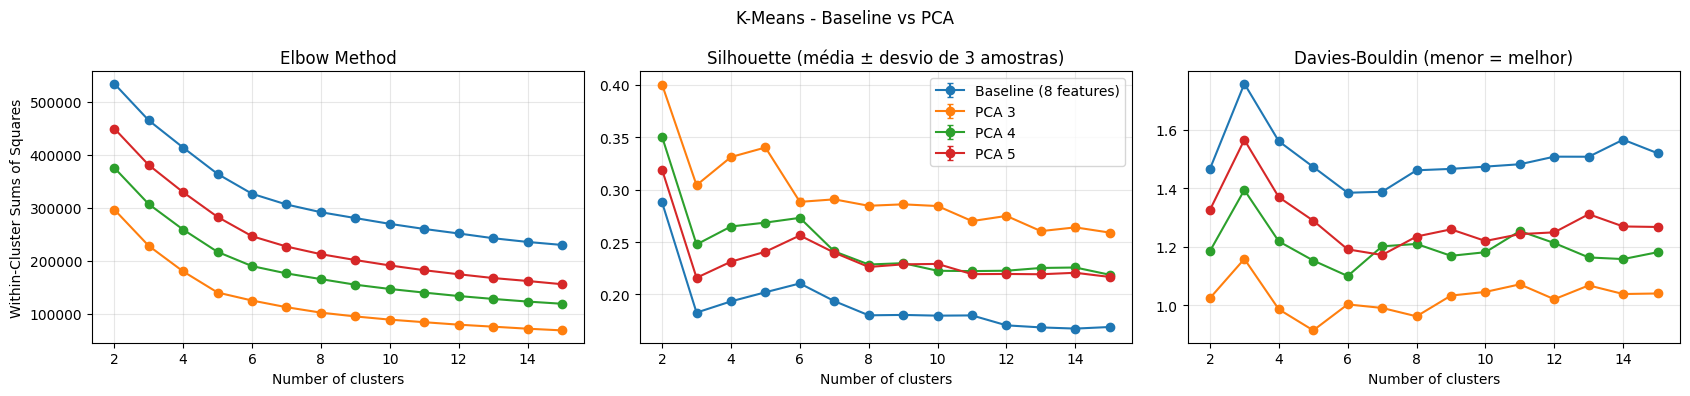

In [32]:
# Elbow, silhouette e Davies-Bouldin por k: compara o baseline com os espaços do PCA.
plot_varredura(pd.concat([res_baseline, res_pca], ignore_index=True), "K-Means - Baseline vs PCA")

### 5. Model Selection

Cada modelo é treinado com os valores de k escolhidos e todas as métricas são calculadas na mesma tabela. O valor de `K_COMPARACAO` pode ser alterado para testar outros k.

#### 5.1 Performance Metrics

In [33]:
# Define os valores de k comparados entre todos os modelos
K_COMPARACAO = [4, 6]

# Define o espaço de referência (8 features) usado nas métricas _8d
X_base = espacos["Baseline (8 features)"]

# Cria o dicionário que guarda o cluster de cada música por modelo: (espaço, k) -> labels
modelos_kmeans = {}

In [34]:
def comparar_kmeans(espacos, ks):
    """Treina o K-Means em cada espaço e k e reúne silhouette, Davies-Bouldin, tamanho dos clusters e métricas de gênero."""
    linhas = []
    for nome, X_modelo in espacos.items():
        for k in ks:
            # Treina o K-Means e guarda o cluster de cada música
            labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_modelo)
            modelos_kmeans[(nome, k)] = labels

            # Calcula o tamanho (%) dos clusters
            serie = pd.Series(labels, index=df_metadata.index)
            tamanhos = serie.value_counts(normalize=True) * 100

            # Calcula silhouette no espaço do modelo e no espaço original (8d)
            sil, _ = silhouette_amostrado(X_modelo, labels)
            sil_8d, _ = silhouette_amostrado(X_base, labels)

            # Reúne todas as métricas do modelo em uma linha
            linhas.append({
                "espaco": nome,
                "k": k,
                "silhouette": sil,
                "silhouette_8d": sil_8d,
                "davies_bouldin": davies_bouldin_score(X_modelo, labels),
                "davies_bouldin_8d": davies_bouldin_score(X_base, labels),
                "maior_cluster_pct": tamanhos.max(),
                "menor_cluster_pct": tamanhos.min(),
                **metricas_genero(serie),
            })
    return pd.DataFrame(linhas)

In [35]:
# Compara o resultado das métricas de performance para todos os modelos
comparacao_kmeans = comparar_kmeans(espacos, K_COMPARACAO)
comparacao_kmeans.round(3)

,espaco,k,silhouette,silhouette_8d,davies_bouldin,davies_bouldin_8d,maior_cluster_pct,menor_cluster_pct,genero_dominante_pct,entropia_generos
0,Baseline (8 features),4,0.193,0.193,1.560,1.560,39.921,7.422,2.991,0.926
1,Baseline (8 features),6,0.210,0.210,1.384,1.384,29.875,6.897,4.257,0.891
2,PCA 3,4,0.331,0.192,0.986,1.570,42.081,7.613,3.006,0.926
3,PCA 3,6,0.288,0.140,1.003,1.727,25.537,7.046,4.063,0.902
4,PCA 4,4,0.265,0.192,1.218,1.568,41.596,7.638,2.994,0.926
5,PCA 4,6,0.273,0.190,1.100,1.479,30.419,6.915,3.898,0.903
6,PCA 5,4,0.231,0.193,1.369,1.559,40.932,7.439,2.990,0.926
7,PCA 5,6,0.256,0.209,1.191,1.390,30.076,6.873,4.197,0.891


- No espaço do próprio modelo, o PCA parece melhorar muito (PCA 3 com k=4: silhouette 0,331 contra 0,193 do baseline). Essa melhora vem de ter menos dimensões: o silhouette não é comparável entre espaços de tamanhos diferentes.
- No referencial das 8 features originais (`silhouette_8d` e `davies_bouldin_8d`), o PCA **não melhora**:
  - PCA 3 piora (silhouette_8d 0,192 em k=4 e 0,140 em k=6, contra 0,193 e 0,210 do baseline);
  - PCA 4 fica igual ou pior (0,192 e 0,190);
  - PCA 5 praticamente reproduz o baseline (0,193 e 0,209).
- O Davies-Bouldin no referencial original conta a mesma história: baseline 1,560 (k=4) e 1,384 (k=6); PCA 3 1,570 e 1,727; PCA 4 1,568 e 1,479; PCA 5 1,559 e 1,390.
- Diversidade de gêneros praticamente não muda: em todos os modelos o gênero mais comum de cada cluster responde por só ~3-4% das músicas, e a entropia de gêneros fica entre 0,89 e 0,93. Os clusters atravessam gêneros com ou sem PCA, e o tamanho dos clusters também é parecido (maior ~25-42% e menor ~7%).
- Isso faz sentido: os 3 primeiros PCs explicam só ~66% da variância, e os últimos componentes carregam informação que o K-Means usa. Os 5 primeiros (~88%) já reproduzem o baseline.

#### 5.2 Perfil dos Clusters

Como a escolha final de k também depende da **interpretabilidade**, a célula abaixo mostra, para cada modelo, a média das 8 features (em desvios-padrão) de cada cluster. Os perfis são sempre calculados nas 8 features originais, mesmo para os modelos treinados no PCA, para dar para comparar. Entre parênteses está o percentual de músicas do cluster.

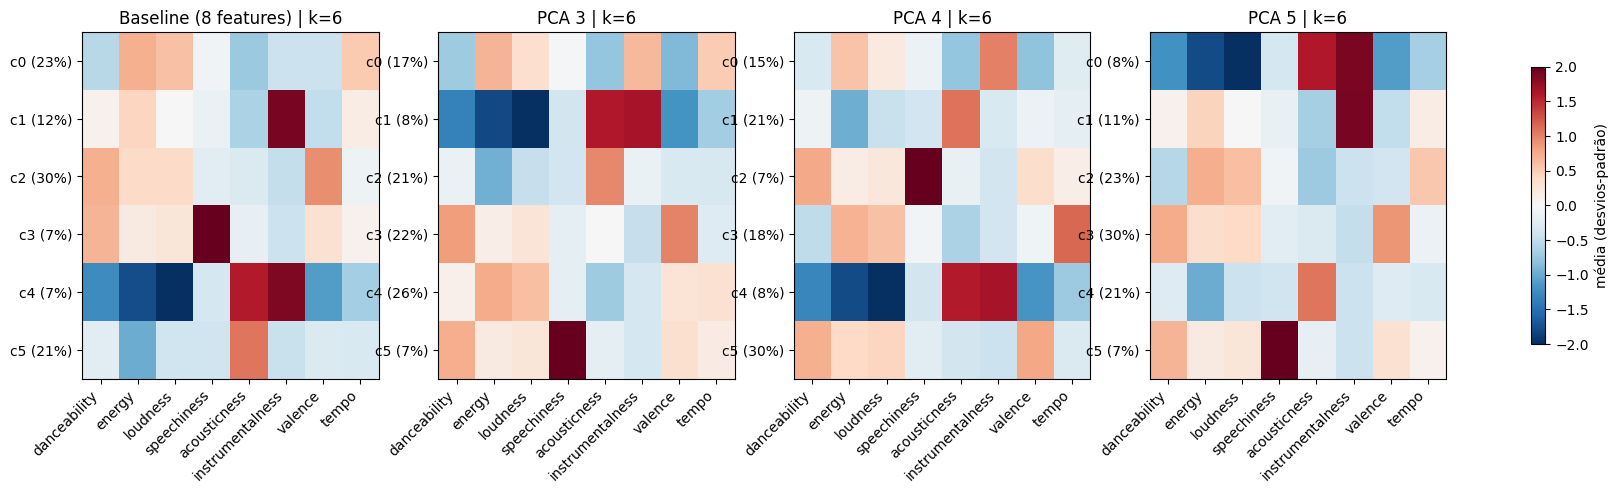

In [36]:
# Define o k usado no perfil (precisa estar em K_COMPARACAO)
K_PERFIL = 6

# Plota o perfil dos clusters de cada modelo: média de cada feature (em desvios-padrão) por cluster
fig, axes = plt.subplots(1, len(espacos), figsize=(5.5 * len(espacos), 4.5))
perfis = {}

for ax, nome in zip(axes, espacos):
    labels = pd.Series(modelos_kmeans[(nome, K_PERFIL)], index=df_metadata.index)
    perfis[nome] = perfil_clusters(labels)
    im = plot_perfil(perfis[nome], f"{nome} | k={K_PERFIL}", ax)

fig.colorbar(im, ax=axes, shrink=0.8, label="média (desvios-padrão)")
plt.show()

In [37]:
# Exibe o percentual de músicas e os gêneros mais comuns de cada cluster
for nome, perfil in perfis.items():
    print(f"\n{nome} | k={K_PERFIL}")
    display(perfil[["pct_musicas", "top_generos"]].round(1))


Baseline (8 features) | k=6


,pct_musicas,top_generos
cluster,,
0,23.2,"metalcore, heavy-metal, grunge"
1,11.6,"minimal-techno, detroit-techno, techno"
2,29.9,"salsa, forro, latino"
3,6.9,"j-dance, dancehall, funk"
4,7.5,"sleep, new-age, classical"
5,20.9,"tango, honky-tonk, jazz"



PCA 3 | k=6


,pct_musicas,top_generos
cluster,,
0,17.1,"grindcore, black-metal, death-metal"
1,7.8,"sleep, new-age, ambient"
2,21.0,"tango, honky-tonk, cantopop"
3,21.5,"salsa, pagode, samba"
4,25.5,"j-idol, party, punk-rock"
5,7.0,"j-dance, dancehall, kids"



PCA 4 | k=6


,pct_musicas,top_generos
cluster,,
0,15.4,"grindcore, minimal-techno, black-metal"
1,20.9,"tango, honky-tonk, cantopop"
2,6.9,"j-dance, dancehall, kids"
3,18.4,"hardstyle, drum-and-bass, happy"
4,8.0,"sleep, new-age, ambient"
5,30.4,"house, latino, disco"



PCA 5 | k=6


,pct_musicas,top_generos
cluster,,
0,7.6,"sleep, new-age, classical"
1,11.5,"minimal-techno, detroit-techno, techno"
2,23.3,"metalcore, heavy-metal, grunge"
3,30.1,"salsa, forro, latino"
4,20.7,"tango, honky-tonk, jazz"
5,6.9,"j-dance, dancehall, funk"


Os clusters do baseline com k=6 são interpretáveis: metal/rock pesado, techno, latino, dance/dancehall, ambient/new-age e tango/jazz/country.

#### 5.3 Visualização dos Clusters (PC1 x PC2)

O scatter de danceability x energy usado antes mostrava só 2 das 8 dimensões. Aqui todos os modelos são desenhados na mesma projeção PC1 x PC2 (a do PCA do Victor), então a diferença entre baseline e PCA aparece nas cores, e não nos eixos.

In [38]:
# Projeta as músicas em PC1 x PC2 (mesma projeção para todos os modelos)
pcs_2d = pca_full.transform(X_scaled)[:, :2]


def plot_pc12(idx, labels, titulo, ax):
    """Dispersão em PC1 x PC2. idx = posições das músicas plotadas; labels = cluster de cada uma (ruído = -1 em cinza)."""
    labels = np.asarray(labels)
    ruido = labels == -1
    ax.scatter(pcs_2d[idx[ruido], 0], pcs_2d[idx[ruido], 1], c="lightgrey", s=3, alpha=0.4)
    ax.scatter(pcs_2d[idx[~ruido], 0], pcs_2d[idx[~ruido], 1], c=labels[~ruido], cmap="tab10", s=4, alpha=0.6)
    ax.set_title(titulo)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

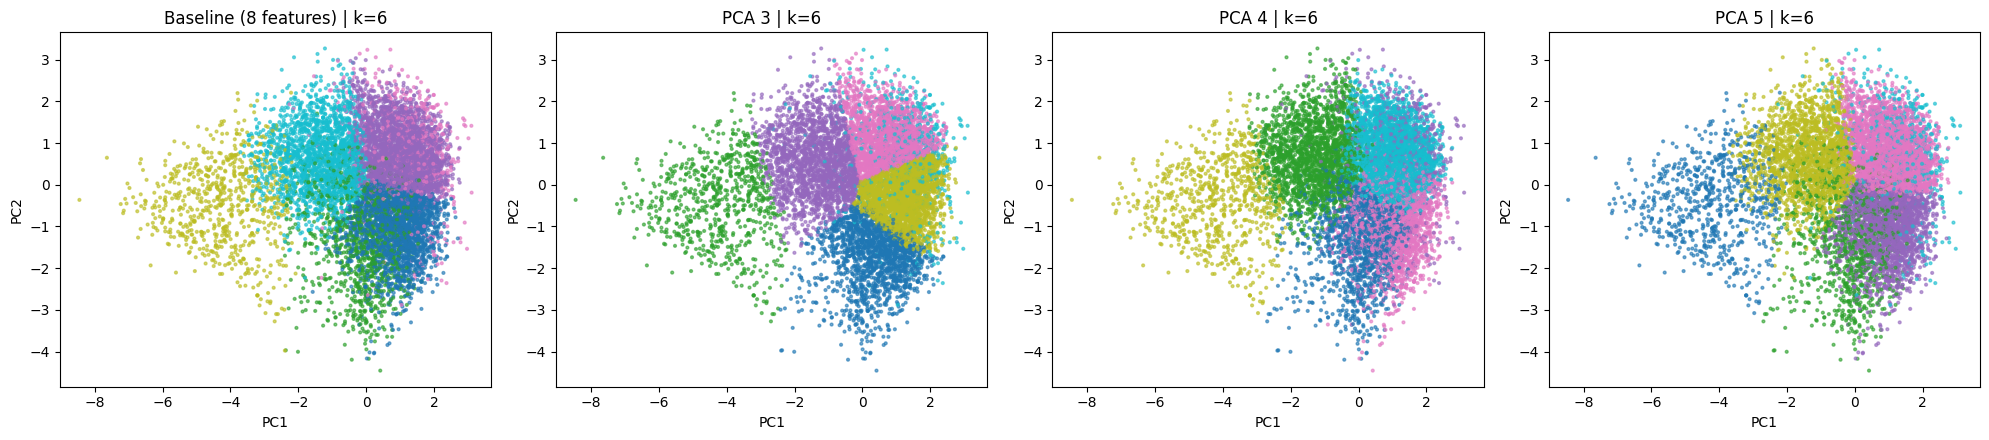

In [39]:
# Seleciona uma amostra de até 10 mil músicas para o gráfico
rng = np.random.RandomState(42)
idx_plot = rng.choice(len(X_scaled), size=min(10000, len(X_scaled)), replace=False)

# Plota os clusters de cada modelo na projeção PC1 x PC2
fig, axes = plt.subplots(1, len(espacos), figsize=(5 * len(espacos), 4.5))

for ax, nome in zip(axes, espacos):
    plot_pc12(idx_plot, modelos_kmeans[(nome, K_PERFIL)][idx_plot], f"{nome} | k={K_PERFIL}", ax)

plt.tight_layout()
plt.show()

### 6. Conclusão

O PCA não melhorou a qualidade do agrupamento. Os resultados sustentam o baseline com k=6 (ou PCA 5, que é equivalente) para o recomendador. O PCA continua útil para visualizar os clusters em 2D e para reduzir dimensionalidade, mas aqui ele não traz ganho de qualidade.